# PSF Weighting, Diffraction, and Scattering Comparison: Review

Reviews a completed `psf-weighting` run. The design and definitions are in
[docs/psf_weighting_comparison.md](../docs/psf_weighting_comparison.md).

Sections:
1. Validation gates and indicative literature checks
2. Goal 2: fraction of light beyond r, F(>r)
3. Goal 1: radial PSF weight profile, P(r)
4. Scene-dependent out-of-frame share (only if the run includes it)

By default the newest run that contains `psf_metadata.csv` is used. Set `RUN_DIR` to choose another run.

In [1]:
from __future__ import annotations

import os
from pathlib import Path

import pandas as pd

from aia_psf_deconvolution.analytics.aggregate import load_results
from aia_psf_deconvolution.analytics.psf_weighting import (
    PSF_LABELS,
    aggregate_out_of_frame,
    comparison_table,
    plot_cumulative_fraction,
    plot_fraction_at_radii,
    plot_out_of_frame,
    plot_radial_profiles,
    radius_label,
    validation_checks,
)

%matplotlib inline
pd.set_option("display.width", 140)

RUNS_ROOT = Path(
    os.environ.get("AIA_RUNS_ROOT", Path.cwd().resolve().parents[1] / "runs")
)
RUN_DIR: Path | None = None  # e.g. RUNS_ROOT / "20261027T210620Z_a2d614b9"

if RUN_DIR is None:
    candidates = sorted(p.parent for p in RUNS_ROOT.glob("*/psf_metadata.csv"))
    if not candidates:
        raise FileNotFoundError(f"No psf-weighting runs under {RUNS_ROOT}")
    RUN_DIR = candidates[-1]

metadata = pd.read_csv(RUN_DIR / "psf_metadata.csv")
table = pd.read_csv(RUN_DIR / "psf_weighting_table.csv")
profiles = pd.read_csv(RUN_DIR / "psf_radial_profiles.csv")
curves = pd.read_csv(RUN_DIR / "psf_cumulative_fraction.csv")
results_path = RUN_DIR / "out_of_frame_results.jsonl"
results = (
    load_results(results_path)
    if results_path.is_file() and results_path.stat().st_size > 0
    else pd.DataFrame()
)

print(f"run: {RUN_DIR.name}")
print(f"PSFs: {len(metadata)}  out-of-frame rows: {len(results)}")
metadata[
    [
        "psf_source",
        "wavelength_angstrom",
        "shape_rows",
        "psf_sum",
        "psf_min",
        "center_fraction",
        "max_distance_px",
    ]
]

run: 20261028T123753Z_e8a037f6
PSFs: 14  out-of-frame rows: 154


,psf_source,wavelength_angstrom,shape_rows,psf_sum,psf_min,center_fraction,max_distance_px
0,grigis_2012,94,4096,1.0,5.032483e-24,0.676271,2896.309376
1,hofmeister_2025,94,8192,1.0,6.462842e-10,0.581974,5792.618751
2,grigis_2012,131,4096,1.0,5.431854e-24,0.655086,2896.309376
3,hofmeister_2025,131,8192,1.0,8.097375e-10,0.472140,5792.618751
4,grigis_2012,171,4096,1.0,8.084607e-24,0.641652,2896.309376
5,hofmeister_2025,171,8192,1.0,5.287020e-10,0.589599,5792.618751
6,grigis_2012,193,4096,1.0,8.404589e-25,0.636516,2896.309376
7,hofmeister_2025,193,8192,1.0,4.016968e-10,0.506778,5792.618751
8,grigis_2012,211,4096,1.0,6.763563e-24,0.633010,2896.309376
9,hofmeister_2025,211,8192,1.0,2.406713e-10,0.564977,5792.618751


## 1. Validation

Rows with `kind == "gate"` must all pass: PSF sum and non-negativity, plus the 171 Å regression values.
Rows with `kind == "indicative"` compare the Hofmeister PSF with values read off the published figures.

In [2]:
checks = validation_checks(table, metadata)
gates = checks[checks["kind"] == "gate"]
print(f"gates passed: {int(gates['passed'].sum())}/{len(gates)}")
indicative = checks[checks["kind"] == "indicative"]
print(f"indicative passed: {int(indicative['passed'].sum())}/{len(indicative)}")
# pd.concat([gates[~gates["passed"]], indicative]).reset_index(drop=True)

gates passed: 35/35
indicative passed: 27/28


## 2. Goal 2: fraction of light beyond r

F(>r) is the share of total PSF weight with d > r. The `>=1 px` column is F(>0), meaning everything except the center pixel.
Values are in percent.

In [3]:
fraction_pct = table.assign(
    radius=table["radius_px"].map(radius_label),
    psf=table["psf_source"].map(PSF_LABELS),
    percent=100 * table["fraction_beyond"],
).pivot_table(
    index=["psf", "wavelength_angstrom"], columns="radius", values="percent", sort=False
)
(
    fraction_pct.style.format("{:.3g}")
    .background_gradient(axis=None, cmap="Reds")
    .set_caption("F(>r): percent of total PSF weight beyond each radius (values in %)")
)

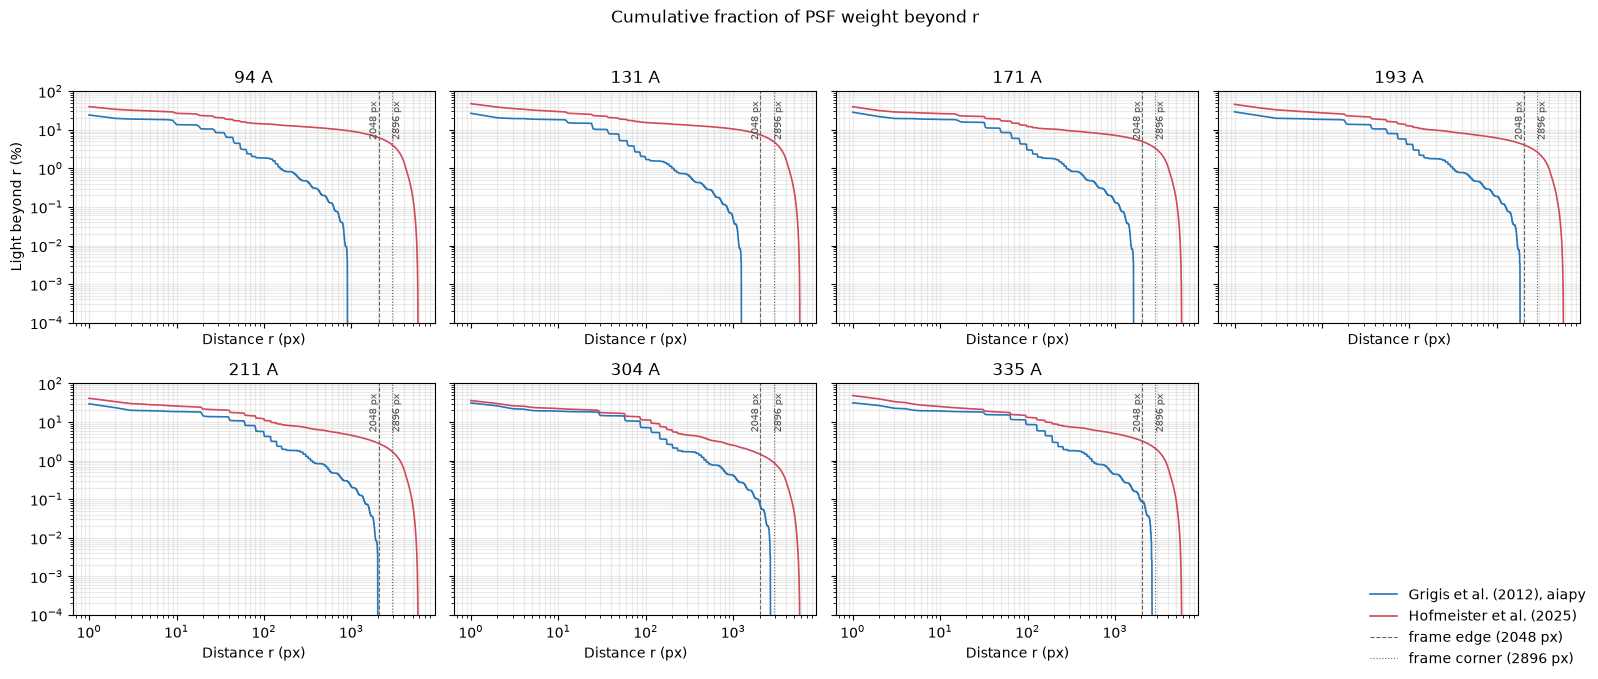

In [4]:
plot_cumulative_fraction(curves);

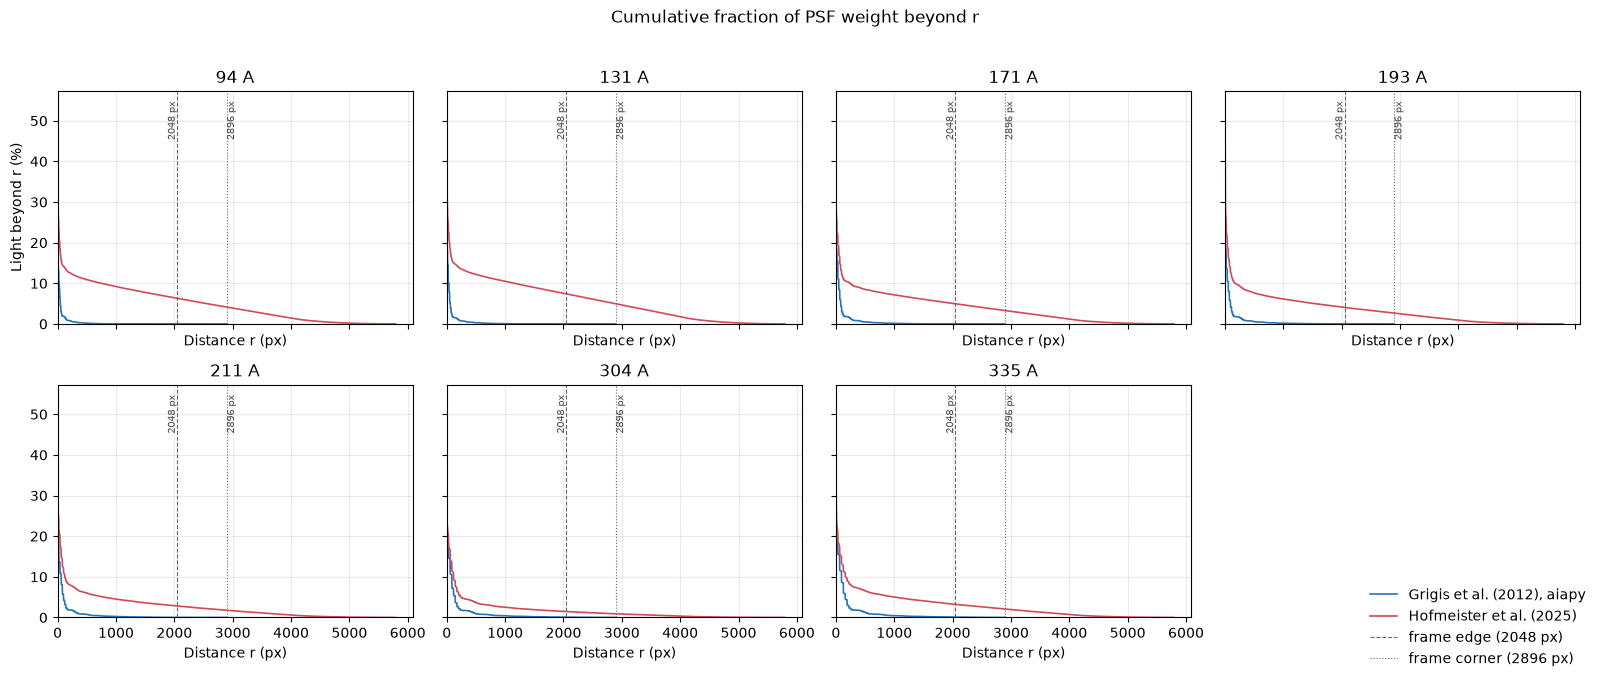

In [5]:
# Same curves on linear axes: shows the steep drop within the first few px and the long, slow far-wing tail.
plot_cumulative_fraction(curves, scale="linear");

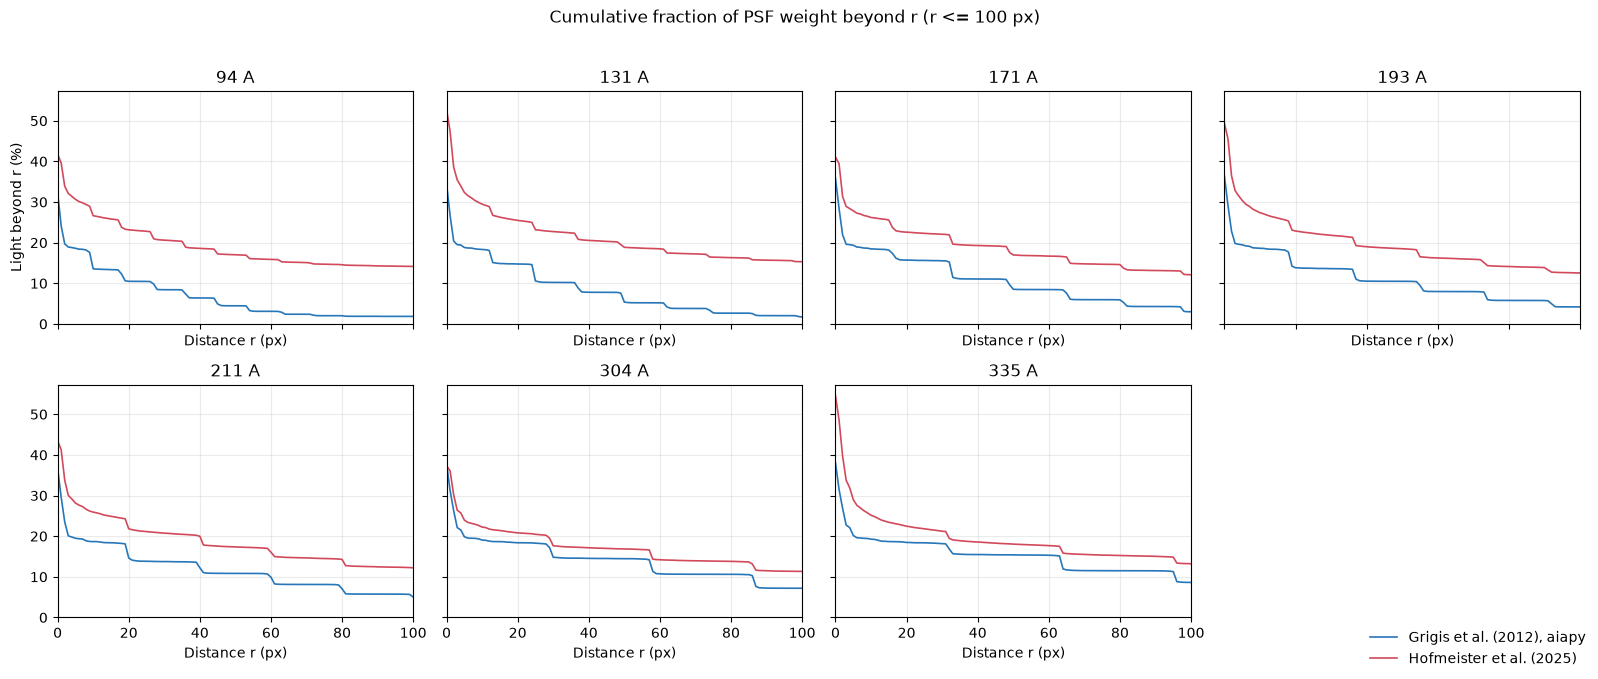

In [6]:
# Linear zoom on the core and near wings (r <= 100 px), where most of the drop happens.
plot_cumulative_fraction(curves, scale="linear", r_max=100);

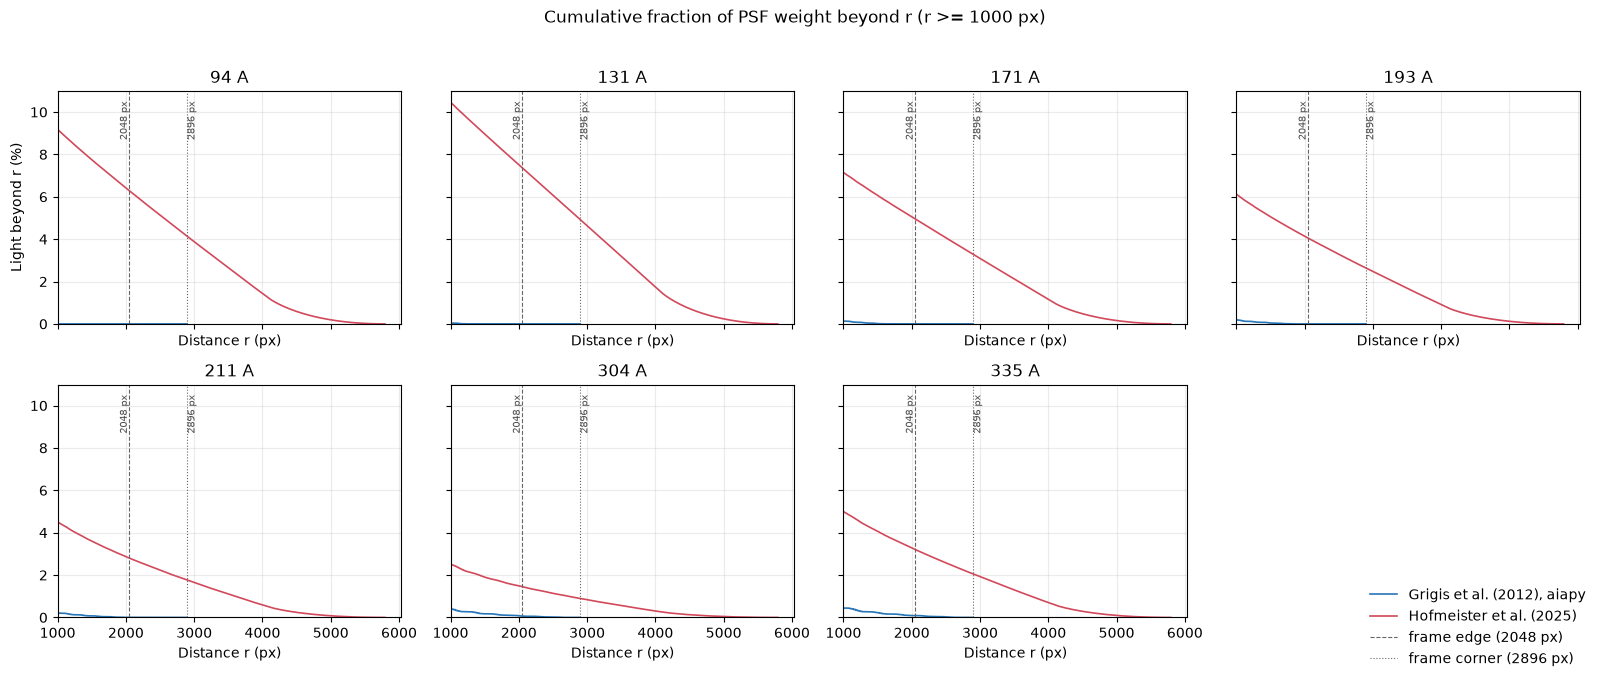

In [7]:
# Linear view of the far wings (r >= 1000 px), around the frame edge and corner.
plot_cumulative_fraction(curves, scale="linear", r_min=1000);

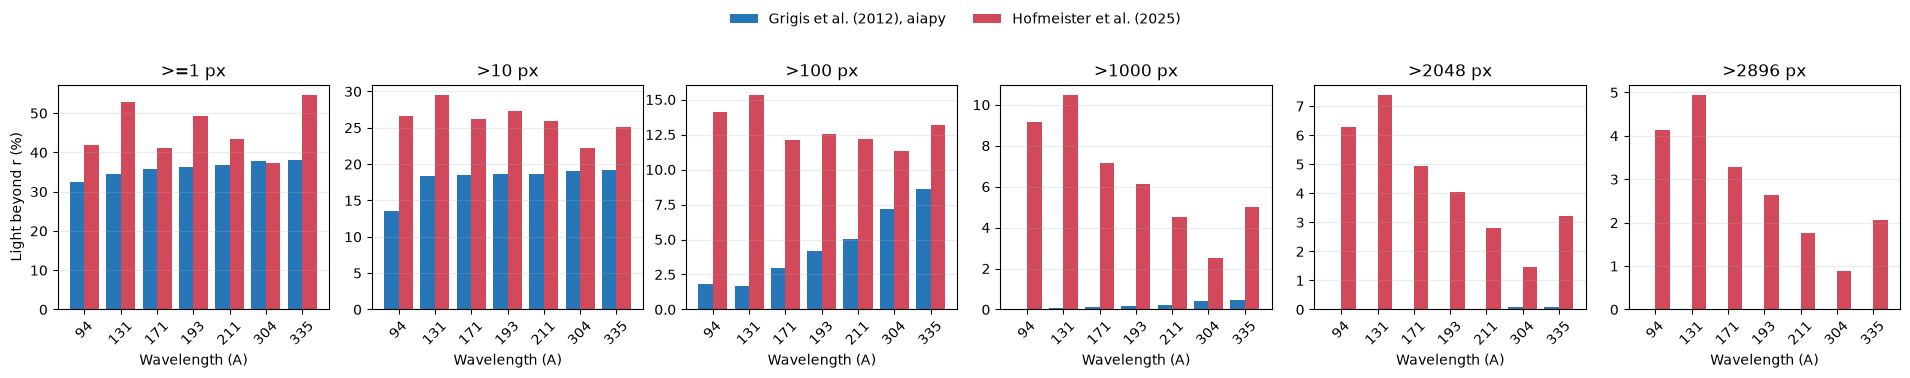

In [8]:
plot_fraction_at_radii(table);

### Hofmeister minus Grigis, in percentage points

This is how much more light the Hofmeister PSF puts beyond each radius than the Grigis PSF does.

In [9]:
wide = comparison_table(table)
(
    wide.assign(pp=100 * wide["fraction_beyond__difference"])
    .pivot(index="wavelength_angstrom", columns="radius_label", values="pp")[
        [radius_label(r) for r in sorted(table["radius_px"].unique())]
    ]
    .style.format("{:+.2f}")
    .background_gradient(axis=None, cmap="RdBu_r", vmin=-10, vmax=10)
    .set_caption("Hofmeister − Grigis F(>r), in percentage points (pp), not relative %")
)

radius_label,>=1 px,>10 px,>100 px,>1000 px,>2048 px,>2896 px
wavelength_angstrom,,,,,,
94,+9.43,+13.07,+12.29,+9.18,+6.29,+4.14
131,+18.29,+11.15,+13.60,+10.41,+7.38,+4.93
171,+5.21,+7.73,+9.12,+7.02,+4.96,+3.29
193,+12.97,+8.75,+8.34,+5.94,+4.05,+2.64
211,+6.80,+7.25,+7.19,+4.31,+2.80,+1.76
304,-0.45,+3.20,+4.15,+2.09,+1.39,+0.90
335,+16.53,+5.89,+4.60,+4.55,+3.12,+2.06


## 3. Goal 1: radial PSF weight profile

P(r) is the mean weight per pixel, with each PSF normalized to unit sum, in a ±0.05 dex annulus around r.
Inside about 300 px the diffraction spikes make the profile jagged, so a single-radius value can land on or between spikes.
Read trends from the figure.

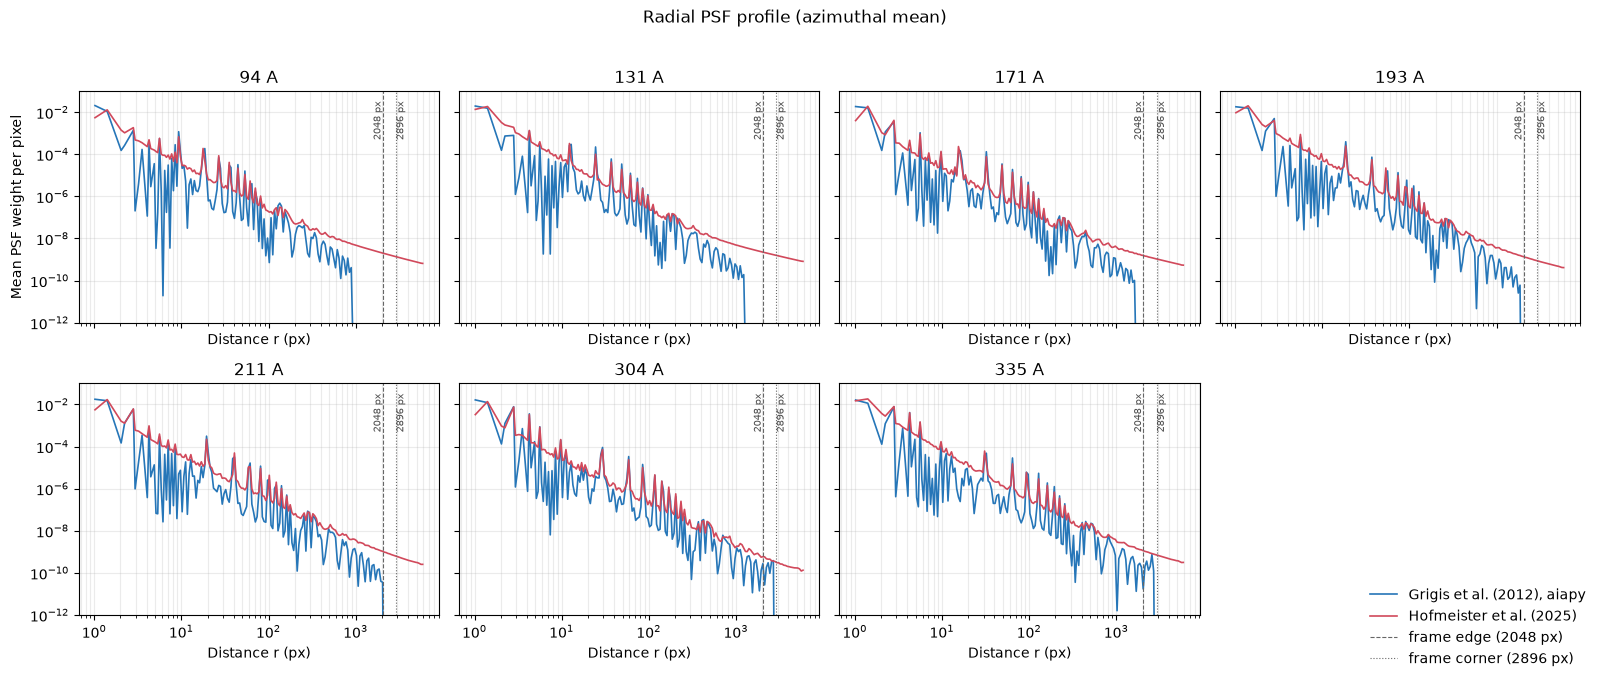

In [10]:
profile = table.assign(psf=table["psf_source"].map(PSF_LABELS)).pivot_table(
    index=["psf", "wavelength_angstrom"],
    columns="radius_px",
    values="profile_mean_weight_normalized",
    sort=False,
)
profile.columns = [f"r = {c} px" for c in profile.columns]
display(profile.style.format("{:.2e}"))
plot_radial_profiles(profiles);

### Annulus completeness

Past the inscribed radius (2047 px for Grigis, 4095 px for Hofmeister) the annuli extend beyond the PSF array.
The mean is then taken over the corners only, and is no longer a full azimuthal average.

In [11]:
table.pivot_table(
    index="psf_source",
    columns="radius_px",
    values="profile_completeness",
    aggfunc="min",
).style.format("{:.3f}")

radius_px,1,10,100,1000,2048,2896
psf_source,,,,,,
grigis_2012,1.000,1.000,1.000,1.000,0.771,0.034
hofmeister_2025,1.000,1.000,1.000,1.000,1.000,1.000


## 4. Scene-dependent out-of-frame share

Each PSF is forward-convolved with its own deconvolved scene: the Richardson–Lucy reference for Grigis and the BID reference for Hofmeister.
The out-of-frame share is the part of that signal that lands outside the 4096² frame.
`flare_saturated` is kept as its own stratum.
These cells are skipped if the run used `--psf-only`.

completed: 154  failed: 0


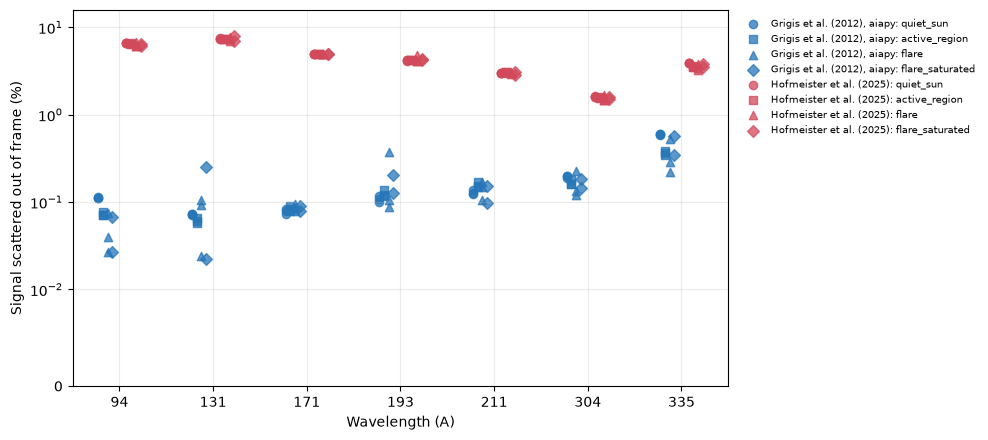

In [12]:
if results.empty:
    print("No out-of-frame results in this run (--psf-only).")
else:
    failed = results[results["status"] != "completed"]
    print(f"completed: {len(results) - len(failed)}  failed: {len(failed)}")
    if not failed.empty:
        display(failed[["psf_source", "image_id", "failure_stage", "failure_reason"]])
    summary = aggregate_out_of_frame(results)
    display(
        summary.assign(mean_pct=100 * summary["mean_share"])
        .pivot_table(
            index=["psf_source", "scene_type"],
            columns="wavelength_angstrom",
            values="mean_pct",
            observed=True,
        )
        .style.format("{:.3g}")
    )
    plot_out_of_frame(results)

### Per-image Hofmeister / Grigis ratio

This compares the two PSFs image by image. A large ratio means Hofmeister scatters much more of that scene's light out of the frame.

In [13]:
if not results.empty and "out_of_frame_share" in results:
    paired = (
        results[results["status"] == "completed"]
        .pivot_table(
            index=["scene_type", "scene_id", "wavelength_angstrom"],
            columns="psf_source",
            values="out_of_frame_share",
        )
        .dropna()
    )
    if {"grigis_2012", "hofmeister_2025"} <= set(paired.columns):
        paired["ratio"] = paired["hofmeister_2025"] / paired["grigis_2012"]
        display((paired * [100, 100, 1]).style.format("{:.3g}"))